<a href="https://colab.research.google.com/github/Chayandas07/Imdb_sentiment_intelligence/blob/main/Sentiment_Analysis_of_IMDb_Movie_Reviews_using_Machine_Learning_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
#  INSTALL REQUIRED LIBRARIES
# ============================================

!pip install -q kagglehub scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
# ============================================
#  IMPORT LIBRARIES
# ============================================

import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import joblib

from collections import Counter

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

# Create output folder
os.makedirs("artifacts", exist_ok=True)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ============================================
# DOWNLOAD IMDb DATASET
# ============================================

print("Downloading IMDb dataset...")

dataset_path = kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

# Locate the CSV file
csv_path = None

for root, dirs, files in os.walk(dataset_path):

    for file in files:

        if file.lower() == "imdb dataset.csv":

            csv_path = os.path.join(root, file)

            break

    if csv_path:
        break

if csv_path is None:
    raise FileNotFoundError("IMDb CSV file not found!")

# Load dataset
df = pd.read_csv(csv_path)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Dataset downloaded successfully!
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
# ============================================
#  DATA CLEANING
# ============================================

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove missing records
df = df.dropna(subset=["review", "sentiment"])

# Remove duplicate reviews
df = df.drop_duplicates(subset=["review"])

# Normalize sentiment labels
df["sentiment"] = (
    df["sentiment"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert sentiment into numerical values
df["sentiment"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

# Remove invalid labels
df = df.dropna(subset=["sentiment"])

df["sentiment"] = df["sentiment"].astype(int)

# Reset index
df = df.reset_index(drop=True)

print("\nDataset after cleaning:")
print(df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Missing values before cleaning:
review       0
sentiment    0
dtype: int64

Dataset after cleaning:
(49582, 2)

Sentiment distribution:
sentiment
1    24884
0    24698
Name: count, dtype: int64


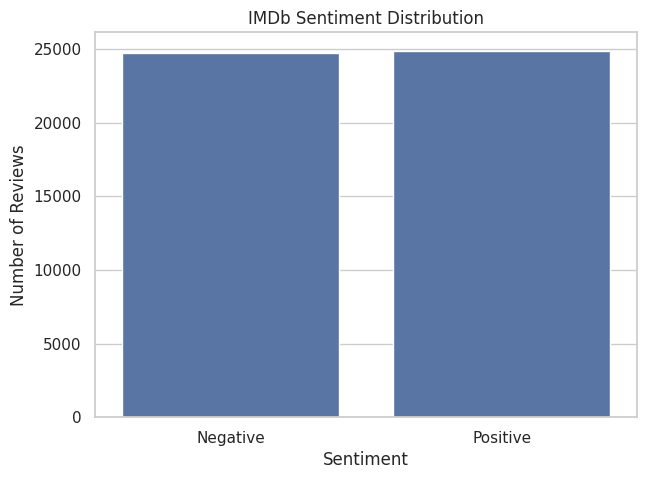

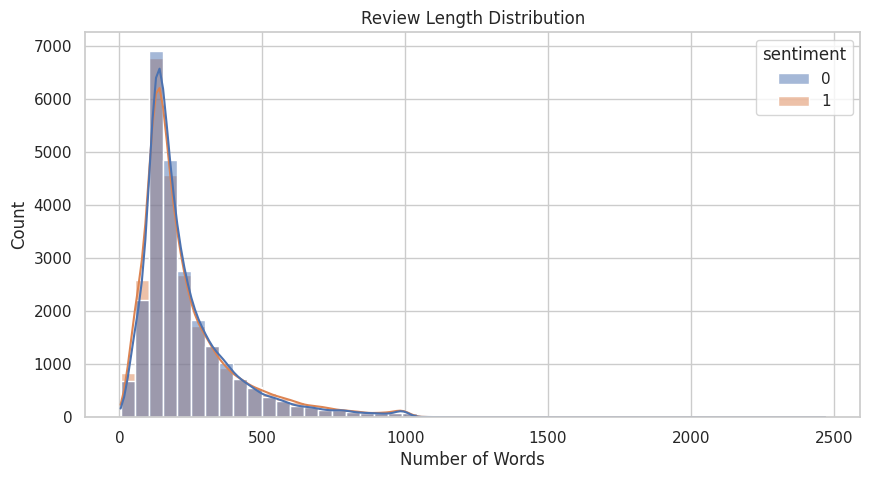


Review length statistics:
             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
0          24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
1          24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


In [5]:
# ============================================
#  EXPLORATORY DATA ANALYSIS
# ============================================

# Visualize positive and negative reviews

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("IMDb Sentiment Distribution")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


# Calculate review length
df["review_length"] = df["review"].apply(
    lambda x: len(str(x).split())
)

# Review length distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    kde=True
)

plt.title("Review Length Distribution")

plt.xlabel("Number of Words")

plt.show()


# Display statistical information
print("\nReview length statistics:")

print(
    df.groupby("sentiment")["review_length"].describe()
)

In [6]:
# ============================================
#  TEXT PREPROCESSING
# ============================================

def clean_text(text):

    # Convert to lowercase
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove unnecessary whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Apply preprocessing
print("Cleaning movie reviews...")

df["cleaned_review"] = df["review"].apply(clean_text)

print("Text preprocessing completed!")

# Compare original and cleaned reviews
print("\nOriginal Review:")
print(df["review"].iloc[0][:500])

print("\nCleaned Review:")
print(df["cleaned_review"].iloc[0][:500])

Cleaning movie reviews...
Text preprocessing completed!

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

Cleaned Review:
one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me. the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or viol

In [7]:
# ============================================
# TRAIN-TEST SPLITTING
# ============================================

X = df["cleaned_review"]

y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y

)

print("Dataset splitting completed!")

print("\nTraining samples:", len(X_train))

print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting sentiment distribution:")
print(y_test.value_counts(normalize=True))

Dataset splitting completed!

Training samples: 39665
Testing samples: 9917

Training sentiment distribution:
sentiment
1    0.501878
0    0.498122
Name: proportion, dtype: float64

Testing sentiment distribution:
sentiment
1    0.501865
0    0.498135
Name: proportion, dtype: float64


In [8]:
# ============================================
#  TF-IDF FEATURE ENGINEERING
# ============================================

tfidf = TfidfVectorizer(

    # Unigrams and bigrams
    ngram_range=(1, 2),

    # Minimum document frequency
    min_df=2,

    # Maximum document frequency
    max_df=0.95,

    # Maximum vocabulary
    max_features=100000,

    # Reduce repeated word frequency influence
    sublinear_tf=True,

    # Unicode normalization
    strip_accents="unicode",

    # Memory optimization
    dtype=np.float32

)

print("Fitting TF-IDF on training data...")

# Learn vocabulary ONLY from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF transformation completed!")

print("Training matrix:", X_train_tfidf.shape)

print("Testing matrix:", X_test_tfidf.shape)

print("Matrix type:", type(X_train_tfidf))

print("Training matrix memory:",
      round(
          (X_train_tfidf.data.nbytes +
           X_train_tfidf.indices.nbytes +
           X_train_tfidf.indptr.nbytes) / (1024 ** 2),
          2
      ), "MB")

Fitting TF-IDF on training data...

TF-IDF transformation completed!
Training matrix: (39665, 100000)
Testing matrix: (9917, 100000)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Training matrix memory: 78.1 MB


In [9]:
# ============================================
#  DEFINE ML MODELS
# ============================================

models = {

    "Naive Bayes": MultinomialNB(
        alpha=0.5
    ),

    "Logistic Regression": LogisticRegression(
        C=2.0,
        max_iter=2000,
        random_state=RANDOM_STATE,
        solver="liblinear"
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        max_iter=3000,
        random_state=RANDOM_STATE
    )

}

print("Three machine learning models created!")

for name in models:

    print("-", name)

Three machine learning models created!
- Naive Bayes
- Logistic Regression
- Linear SVM


In [10]:
# ============================================
# MODEL TRAINING AND CROSS-VALIDATION
# ============================================

cv = StratifiedKFold(

    n_splits=3,

    shuffle=True,

    random_state=RANDOM_STATE

)

results = []

trained_models = {}

print("Starting cross-validation...\n")

for name, model in models.items():

    print("=" * 55)

    print("Training:", name)

    start_time = time.time()

    # Cross-validation
    scores = cross_validate(

        model,

        X_train_tfidf,

        y_train,

        cv=cv,

        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },

        n_jobs=-1,

        return_train_score=False

    )

    elapsed = time.time() - start_time

    # Train model on complete training dataset
    model.fit(
        X_train_tfidf,
        y_train
    )

    trained_models[name] = model

    results.append({

        "Model": name,

        "CV Accuracy": scores["test_accuracy"].mean(),

        "CV Precision": scores["test_precision"].mean(),

        "CV Recall": scores["test_recall"].mean(),

        "CV F1": scores["test_f1"].mean(),

        "CV F1 Std": scores["test_f1"].std(),

        "Training Time (s)": elapsed

    })

    print(
        f"Cross-validation F1: "
        f"{scores['test_f1'].mean():.4f}"
    )

    print(
        f"Execution time: {elapsed:.2f} seconds"
    )


# Create comparison table
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="CV F1",
    ascending=False
)

print("\nFINAL MODEL COMPARISON")

display(comparison_df)

Starting cross-validation...

Training: Naive Bayes
Cross-validation F1: 0.8867
Execution time: 2.38 seconds
Training: Logistic Regression
Cross-validation F1: 0.9075
Execution time: 6.28 seconds
Training: Linear SVM
Cross-validation F1: 0.9102
Execution time: 3.39 seconds

FINAL MODEL COMPARISON


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std,Training Time (s)
2,Linear SVM,0.909189,0.903895,0.916512,0.910157,0.000623,3.391729
1,Logistic Regression,0.906290,0.899292,0.915859,0.907492,0.001097,6.283906
0,Naive Bayes,0.886424,0.887870,0.885568,0.886707,0.001443,2.379867


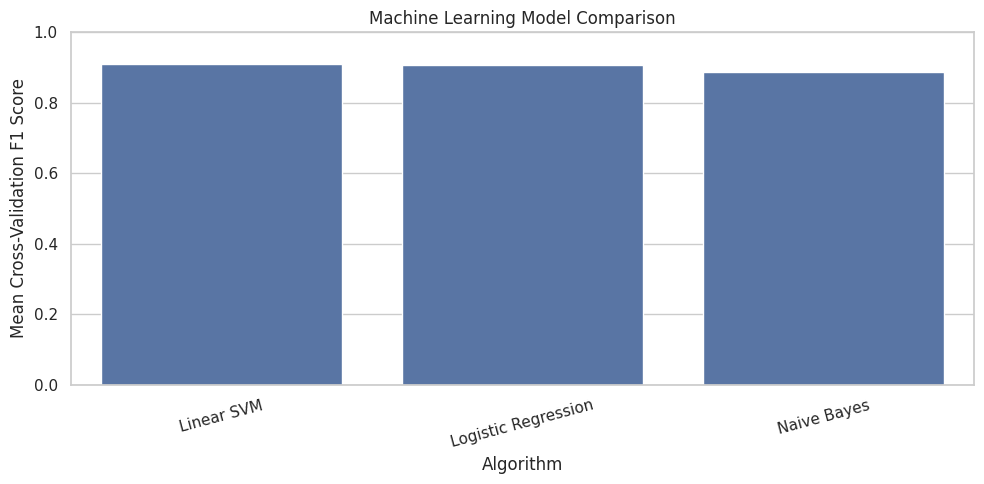

In [11]:
# ============================================
#  MODEL COMPARISON VISUALIZATION
# ============================================

plt.figure(figsize=(10, 5))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="CV F1"

)

plt.title("Machine Learning Model Comparison")

plt.xlabel("Algorithm")

plt.ylabel("Mean Cross-Validation F1 Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

In [12]:
# ============================================
# LINEAR SVM HYPERPARAMETER TUNING
# ============================================

print("Starting Linear SVM optimization...")

svm_grid = {

    "C": [0.5, 1.0, 2.0, 3.0]

}

grid_search = GridSearchCV(

    estimator=LinearSVC(
        max_iter=3000,
        random_state=RANDOM_STATE
    ),

    param_grid=svm_grid,

    scoring="f1",

    cv=cv,

    n_jobs=-1,

    verbose=1,

    refit=True

)

start_time = time.time()

grid_search.fit(
    X_train_tfidf,
    y_train
)

tuning_time = time.time() - start_time

print("\nOptimization completed!")

print("\nBest parameters:")

print(grid_search.best_params_)

print("\nBest cross-validation F1:")

print(grid_search.best_score_)

print("\nOptimization time:")

print(f"{tuning_time:.2f} seconds")


# Save optimized SVM
best_svm = grid_search.best_estimator_

trained_models["Optimized Linear SVM"] = best_svm

Starting Linear SVM optimization...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Optimization completed!

Best parameters:
{'C': 0.5}

Best cross-validation F1:
0.9113828196609063

Optimization time:
17.10 seconds


In [13]:
# ============================================
#  FINAL MODEL SELECTION
# ============================================

# Add optimized SVM to comparison results
tuned_result = {

    "Model": "Optimized Linear SVM",

    "CV Accuracy": np.nan,

    "CV Precision": np.nan,

    "CV Recall": np.nan,

    "CV F1": grid_search.best_score_,

    "CV F1 Std": np.nan,

    "Training Time (s)": tuning_time

}

comparison_df = pd.concat(

    [
        comparison_df,
        pd.DataFrame([tuned_result])
    ],

    ignore_index=True

)

# Select the model with the highest CV F1
best_model_name = comparison_df.loc[
    comparison_df["CV F1"].idxmax(),
    "Model"
]

best_classifier = trained_models[best_model_name]

print("Selected Model:", best_model_name)

print("Best CV F1:", comparison_df["CV F1"].max())

display(
    comparison_df.sort_values(
        "CV F1",
        ascending=False
    )
)

Selected Model: Optimized Linear SVM
Best CV F1: 0.9113828196609063


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std,Training Time (s)
3,Optimized Linear SVM,NaN,NaN,NaN,0.911383,NaN,17.095555
0,Linear SVM,0.909189,0.903895,0.916512,0.910157,0.000623,3.391729
1,Logistic Regression,0.906290,0.899292,0.915859,0.907492,0.001097,6.283906
2,Naive Bayes,0.886424,0.887870,0.885568,0.886707,0.001443,2.379867


In [14]:
# ============================================
#  BUILD FINAL PIPELINE
# ============================================

from sklearn.base import clone

# Create a fresh vectorizer
final_vectorizer = TfidfVectorizer(

    ngram_range=(1, 2),

    min_df=2,

    max_df=0.95,

    max_features=100000,

    sublinear_tf=True,

    strip_accents="unicode",

    dtype=np.float32

)

# Create complete NLP + ML pipeline
final_pipeline = Pipeline([

    ("tfidf", final_vectorizer),

    ("classifier", clone(best_classifier))

])

print("Training final pipeline...")

start_time = time.time()

# Fit the complete pipeline on raw cleaned training reviews
final_pipeline.fit(
    X_train,
    y_train
)

final_training_time = time.time() - start_time

print("Final pipeline trained successfully!")

print(
    f"Final training time: {final_training_time:.2f} seconds"
)

Training final pipeline...
Final pipeline trained successfully!
Final training time: 27.88 seconds


In [15]:
# ============================================
#  FINAL MODEL EVALUATION
# ============================================

# Predict test sentiment
y_pred = final_pipeline.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

# Obtain ranking scores for ROC-AUC
classifier = final_pipeline.named_steps["classifier"]

if hasattr(classifier, "decision_function"):

    y_score = final_pipeline.decision_function(X_test)

else:

    y_score = final_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_score)


# Store metrics
final_metrics = {

    "Model": best_model_name,

    "Accuracy": accuracy,

    "Precision": precision,

    "Recall": recall,

    "F1 Score": f1,

    "ROC-AUC": roc_auc

}

# Display results
print("=" * 55)

print("FINAL TEST PERFORMANCE")

print("=" * 55)

for metric, value in final_metrics.items():

    if isinstance(value, (float, np.floating)):

        print(f"{metric:<15}: {value:.4f}")

    else:

        print(f"{metric:<15}: {value}")


print("\nClassification Report:\n")

print(

    classification_report(

        y_test,

        y_pred,

        target_names=[
            "Negative",
            "Positive"
        ]

    )

)

FINAL TEST PERFORMANCE
Model          : Optimized Linear SVM
Accuracy       : 0.9147
Precision      : 0.9070
Recall         : 0.9249
F1 Score       : 0.9158
ROC-AUC        : 0.9728

Classification Report:

              precision    recall  f1-score   support

    Negative       0.92      0.90      0.91      4940
    Positive       0.91      0.92      0.92      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



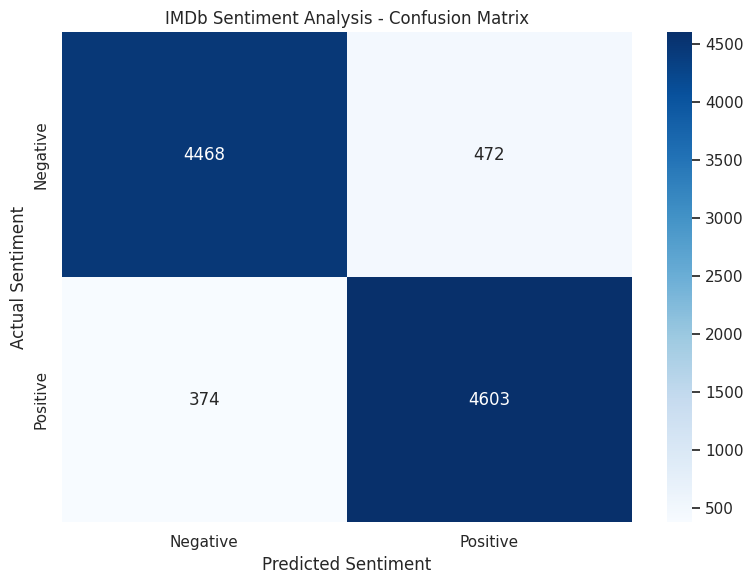

In [16]:
# ============================================
#  CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=[
        "Negative",
        "Positive"
    ],

    yticklabels=[
        "Negative",
        "Positive"
    ]

)

plt.title("IMDb Sentiment Analysis - Confusion Matrix")

plt.xlabel("Predicted Sentiment")

plt.ylabel("Actual Sentiment")

plt.tight_layout()

plt.savefig(
    "artifacts/confusion_matrix.png",
    dpi=300
)

plt.show()

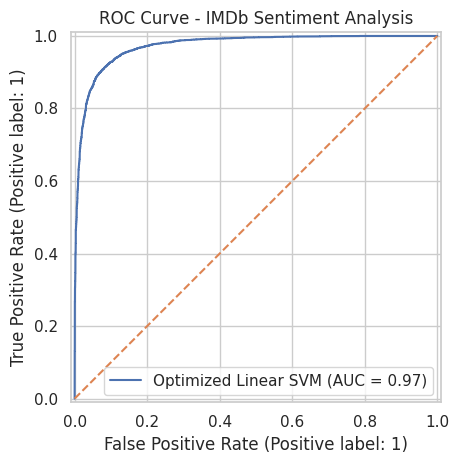

ROC-AUC: 0.9728


In [17]:
# ============================================
#  ROC CURVE
# ============================================

RocCurveDisplay.from_predictions(

    y_test,

    y_score,

    name=best_model_name

)

plt.title("ROC Curve - IMDb Sentiment Analysis")

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.tight_layout()

plt.savefig(
    "artifacts/roc_curve.png",
    dpi=300
)

plt.show()

print("ROC-AUC:", round(roc_auc, 4))

In [18]:
# ============================================
#  EXPLAINABLE AI
# ============================================

classifier = final_pipeline.named_steps["classifier"]

vectorizer = final_pipeline.named_steps["tfidf"]

feature_names = vectorizer.get_feature_names_out()

# Extract model importance
if hasattr(classifier, "coef_"):

    # Linear SVM / Logistic Regression
    coefficients = classifier.coef_[0]

elif hasattr(classifier, "feature_log_prob_"):

    # Naive Bayes
    coefficients = (
        classifier.feature_log_prob_[1]
        - classifier.feature_log_prob_[0]
    )

else:

    raise ValueError("Unsupported classifier for feature analysis.")


feature_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": coefficients

})

# Top positive features
positive_features = feature_importance.nlargest(
    20,
    "Importance"
)

# Top negative features
negative_features = feature_importance.nsmallest(
    20,
    "Importance"
)

print("TOP POSITIVE FEATURES")

display(positive_features)

print("TOP NEGATIVE FEATURES")

display(negative_features)


# Save complete feature importance
feature_importance.sort_values(
    "Importance",
    ascending=False
).to_csv(
    "artifacts/top_features.csv",
    index=False
)

TOP POSITIVE FEATURES


,Feature,Importance
34449,great,3.726238
27231,excellent,3.178785
63410,perfect,2.828705
3486,amazing,2.379578
98197,wonderful,2.281724
89420,today,2.150463
13851,brilliant,2.139900
25939,enjoyable,2.019903
32153,fun,1.986715
38109,hilarious,1.960242


TOP NEGATIVE FEATURES


,Feature,Importance
98604,worst,-4.099855
9831,awful,-3.944222
10015,bad,-3.800321
13337,boring,-3.374623
64843,poor,-3.150566
79792,terrible,-2.979026
85065,the worst,-2.959677
94461,waste,-2.834457
22971,disappointment,-2.422397
57357,nothing,-2.414353


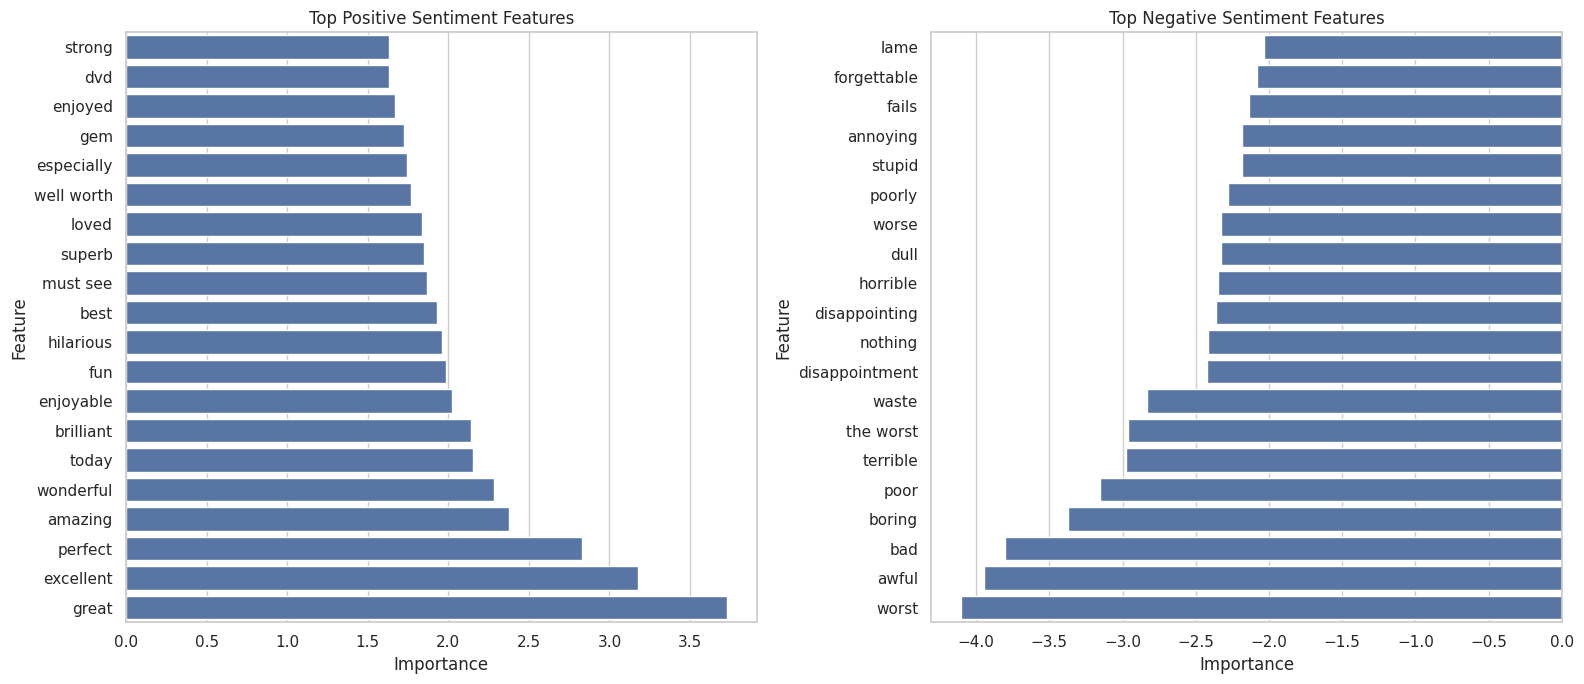

In [19]:
# ============================================
#  FEATURE IMPORTANCE VISUALIZATION
# ============================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# Positive features
sns.barplot(

    data=positive_features.sort_values(
        "Importance",
        ascending=True
    ),

    x="Importance",

    y="Feature",

    ax=axes[0]

)

axes[0].set_title("Top Positive Sentiment Features")


# Negative features
sns.barplot(

    data=negative_features.sort_values(
        "Importance",
        ascending=False
    ),

    x="Importance",

    y="Feature",

    ax=axes[1]

)

axes[1].set_title("Top Negative Sentiment Features")

plt.tight_layout()

plt.savefig(
    "artifacts/feature_importance.png",
    dpi=300
)

plt.show()

In [20]:
# ============================================
# SAVE FINAL MODEL
# ============================================

model_artifact = {

    "pipeline": final_pipeline,

    "model_name": best_model_name,

    "metrics": final_metrics,

    "random_state": RANDOM_STATE,

    "dataset": "IMDb 50K Movie Reviews",

    "version": "1.0"

}

# Save trained model
joblib.dump(

    model_artifact,

    "artifacts/imdb_sentiment_model.joblib",

    compress=3

)

# Save comparison table
comparison_df.to_csv(

    "artifacts/model_comparison.csv",

    index=False

)

# Save final evaluation metrics
pd.DataFrame(
    [final_metrics]
).to_csv(
    "artifacts/final_metrics.csv",
    index=False
)

print("Model and evaluation artifacts saved!")

print("\nSaved files:")

for file in os.listdir("artifacts"):

    print("-", file)

Model and evaluation artifacts saved!

Saved files:
- top_features.csv
- imdb_sentiment_model.joblib
- model_comparison.csv
- feature_importance.png
- final_metrics.csv
- confusion_matrix.png
- roc_curve.png


In [21]:
# ============================================
#  CUSTOM SENTIMENT PREDICTION
# ============================================

def predict_sentiment(review):

    # Reject empty input
    if not isinstance(review, str) or not review.strip():

        return {
            "Sentiment": "Invalid input",
            "Decision Score": None
        }

    # Predict sentiment
    prediction = final_pipeline.predict([review])[0]

    # Obtain model decision score
    decision_score = final_pipeline.decision_function(
        [review]
    )[0]

    # Interpret prediction
    sentiment = (
        "Positive 😊"
        if prediction == 1
        else "Negative 😞"
    )

    return {

        "Sentiment": sentiment,

        "Decision Score": round(
            float(decision_score),
            4
        ),

        "Interpretation": (
            "Positive side of the decision boundary"
            if decision_score >= 0
            else "Negative side of the decision boundary"
        )

    }


# Test examples
test_reviews = [

    "This movie was absolutely fantastic. "
    "The acting and storyline were brilliant.",

    "The movie was boring and disappointing. "
    "A complete waste of time.",

    "The cinematography was beautiful, "
    "but the screenplay was weak.",

    "I loved every moment of this incredible movie."

]

for review in test_reviews:

    print("\nReview:")
    print(review)

    print("\nPrediction:")
    print(predict_sentiment(review))

    print("-" * 60)


Review:
This movie was absolutely fantastic. The acting and storyline were brilliant.

Prediction:
{'Sentiment': 'Positive 😊', 'Decision Score': 0.6424, 'Interpretation': 'Positive side of the decision boundary'}
------------------------------------------------------------

Review:
The movie was boring and disappointing. A complete waste of time.

Prediction:
{'Sentiment': 'Negative 😞', 'Decision Score': -3.265, 'Interpretation': 'Negative side of the decision boundary'}
------------------------------------------------------------

Review:
The cinematography was beautiful, but the screenplay was weak.

Prediction:
{'Sentiment': 'Negative 😞', 'Decision Score': -0.4752, 'Interpretation': 'Negative side of the decision boundary'}
------------------------------------------------------------

Review:
I loved every moment of this incredible movie.

Prediction:
{'Sentiment': 'Positive 😊', 'Decision Score': 0.9445, 'Interpretation': 'Positive side of the decision boundary'}
------------------

In [22]:
# ============================================
# INSTALL GRADIO
# ============================================

!pip install -q gradio

In [23]:
# ============================================
#  GRADIO WEB APPLICATION
# ============================================

import gradio as gr


def analyze_movie_review(review):

    if not review or not review.strip():

        return "Please enter a movie review.", ""

    result = predict_sentiment(review)

    sentiment = result["Sentiment"]

    score = result["Decision Score"]

    interpretation = result["Interpretation"]

    output = f"""
    ### Predicted Sentiment: {sentiment}

    **SVM Decision Score:** {score}

    **Interpretation:** {interpretation}
    """

    return sentiment, output


# Create Gradio interface
demo = gr.Interface(

    fn=analyze_movie_review,

    inputs=gr.Textbox(

        lines=6,

        placeholder="Enter your movie review here...",

        label="Movie Review"

    ),

    outputs=[

        gr.Textbox(label="Sentiment"),

        gr.Markdown(label="Model Analysis")

    ],

    title="🎬 IMDb Sentiment Intelligence",

    description=(
        "AI-powered movie review sentiment classification "
        "using NLP and Machine Learning."
    ),

    examples=[

        [
            "This movie was fantastic. "
            "The acting was brilliant."
        ],

        [
            "Terrible movie. "
            "The story was boring and disappointing."
        ]

    ]

)


# Launch application
demo.launch(
    share=True,
    debug=False
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://86b2bd53b4c0a41a62.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
